# Тема 3. Применение условных вероятностей в анализе данных

**Набор данных: Rain in Australia**

В этой работе на реальном наборе данных будет показано, как **условная вероятность**
помогает извлекать из данных полезную информацию. Для примера возьмём набор
данных о погоде в Австралии и ответим на вопрос:

> *Насколько меняется вероятность того, что **завтра пойдёт дождь**, если мы знаем
> дополнительные факты — шёл ли дождь сегодня, какая была влажность воздуха,
> в каком городе мы находимся?*


## 1. Загрузка данных и их описание


In [ ]:
import io
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

url = "https://www.kaggle.com/api/v1/datasets/download/jsphyg/weather-dataset-rattle-package"

response = requests.get(url, timeout=120)
response.raise_for_status()

if not response.content.startswith(b"PK"):
    raise RuntimeError(
        "Kaggle не вернул ZIP-архив. Возможно, для скачивания нужна авторизация."
    )

data_dir = Path("data/rain_in_australia")
data_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    archive.extractall(data_dir)

csv_files = list(data_dir.rglob("weatherAUS.csv"))

df = pd.read_csv(csv_files[0])

print("Размер датасета:", df.shape)
display(df.head())


Размер датасета: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [4]:
print("Информация о столбцах:")
df.info()

Информация о столбцах:
<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89

In [2]:
print("\nТоп-10 признаков по числу пропусков:")
print(df.isna().sum().sort_values(ascending=False).head(10))


Топ-10 признаков по числу пропусков:
Sunshine         69835
Evaporation      62790
Cloud3pm         59358
Cloud9am         55888
Pressure9am      15065
Pressure3pm      15028
WindDir9am       10566
WindGustDir      10326
WindGustSpeed    10263
Humidity3pm       4507
dtype: int64


In [3]:
print("\nРаспределение целевого признака RainTomorrow:")
print(df["RainTomorrow"].value_counts(dropna=False))


Распределение целевого признака RainTomorrow:
RainTomorrow
No     110316
Yes     31877
NaN      3267
Name: count, dtype: int64


## 2. Теория: условная вероятность

Условная вероятность события $A$ при условии, что произошло событие $B$,
определяется как

$$P(A \mid B) = \frac{P(A \cap B)}{P(B)}, \qquad P(B) > 0.$$

Например,

$$P(\text{дождь завтра} \mid \text{дождь сегодня}) =
\frac{P(\text{дождь сегодня и дождь завтра})}
     {P(\text{дождь сегодня})}.$$

Сравнивая $P(A)$ и $P(A \mid B)$, мы видим, **несёт ли признак $B$ информацию**
о событии $A$. Если вероятности отличаются — признаки зависимы.


In [3]:
# Переведём категориальные признаки "Yes"/"No" в логические значения
data = df.dropna(subset=["RainTomorrow", "RainToday"]).copy()
data["rain_tomorrow"] = data["RainTomorrow"].eq("Yes")
data["rain_today"] = data["RainToday"].eq("Yes")

# Безусловная (априорная) вероятность дождя завтра
p_rain = data["rain_tomorrow"].mean()

print(f"Число наблюдений после удаления пропусков: {len(data):,}")
print(f"P(дождь завтра) = P(RainTomorrow = Yes) = {p_rain:.3f}  ({p_rain:.1%})")


Число наблюдений после удаления пропусков: 140,787
P(дождь завтра) = P(RainTomorrow = Yes) = 0.222  (22.2%)


## 3. Условие №1: шёл ли дождь сегодня?

Проверим гипотезу «если сегодня дождь, то и завтра вероятнее дождь».
Сравним $P(\text{дождь завтра})$ и
$P(\text{дождь завтра} \mid \text{дождь сегодня})$.


In [4]:
p_rain_given_today = data[data["rain_today"]]["rain_tomorrow"].mean()
p_rain_given_dry = data[~data["rain_today"]]["rain_tomorrow"].mean()

print(f"P(дождь завтра)                      = {p_rain:.3f}")
print(f"P(дождь завтра | сегодня дождь)      = {p_rain_given_today:.3f}")
print(f"P(дождь завтра | сегодня сухо)       = {p_rain_given_dry:.3f}")
print()
print(f"Во сколько раз знание о дожде сегодня "
      f"меняет вероятность: {p_rain_given_today / p_rain:.2f}x")


P(дождь завтра)                      = 0.222
P(дождь завтра | сегодня дождь)      = 0.464
P(дождь завтра | сегодня сухо)       = 0.152

Во сколько раз знание о дожде сегодня меняет вероятность: 2.09x


In [ ]:
# Таблица сопряжённости количества наблюдений
contingency = pd.crosstab(data["rain_today"], data["rain_tomorrow"], margins=True)
contingency.index = ["Сегодня сухо", "Сегодня дождь", "Всего"]
contingency.columns = ["Завтра сухо", "Завтра дождь", "Всего"]
display(contingency)

# Условная вероятность дождя внутри каждой группы
by_today = data.groupby("rain_today")["rain_tomorrow"].agg(["count", "sum", "mean"])
by_today.index = ["Сегодня сухо", "Сегодня дождь"]
by_today.columns = ["Наблюдений", "Дождливых дней", "P(дождь завтра)"]
display(by_today.round(3))


,Завтра сухо,Завтра дождь,Всего
Сегодня сухо,92728,16604,109332
Сегодня дождь,16858,14597,31455
Всего,109586,31201,140787


,Наблюдений,Дождливых дней,P(дождь завтра)
Сегодня сухо,109332,16604,0.152
Сегодня дождь,31455,14597,0.464


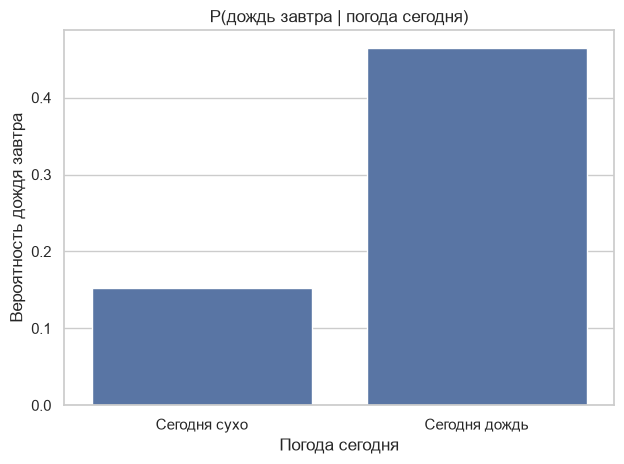

In [6]:
ax = sns.barplot(data=data, x="rain_today", y="rain_tomorrow", errorbar=None)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Сегодня сухо", "Сегодня дождь"])
ax.set_xlabel("Погода сегодня")
ax.set_ylabel("Вероятность дождя завтра")
ax.set_title("P(дождь завтра | погода сегодня)")
plt.tight_layout()
plt.show()


## 4. Условие №2: влажность воздуха

Теперь рассмотрим признак `Humidity3pm` (влажность в 15:00). Разобьём дни на две
группы — влажность **не меньше медианы** и **меньше медианы** — и посмотрим,
как отличается условная вероятность дождя.


In [7]:
humidity_median = data["Humidity3pm"].median()
data["high_humidity"] = data["Humidity3pm"] >= humidity_median

p_given_humid = data[data["high_humidity"]]["rain_tomorrow"].mean()
p_given_dryair = data[~data["high_humidity"]]["rain_tomorrow"].mean()

print(f"Медиана влажности в 15:00: {humidity_median:.1f}%")
print(f"P(дождь завтра | влажность >= медианы) = {p_given_humid:.3f}")
print(f"P(дождь завтра | влажность <  медианы) = {p_given_dryair:.3f}")


Медиана влажности в 15:00: 52.0%
P(дождь завтра | влажность >= медианы) = 0.359
P(дождь завтра | влажность <  медианы) = 0.087


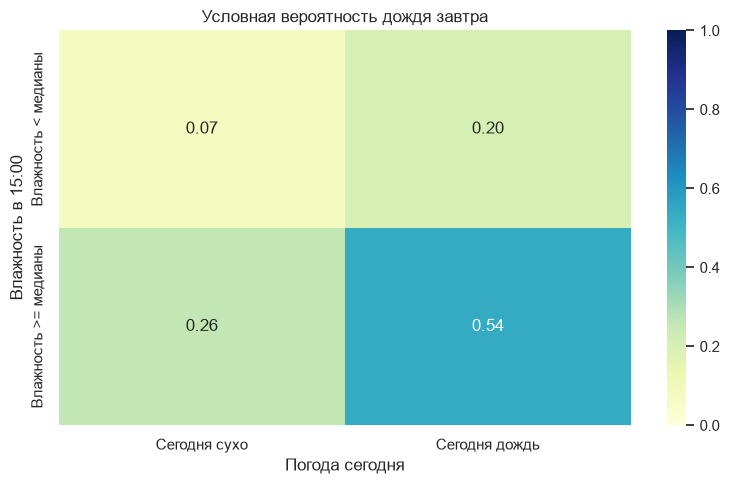

In [8]:
# Совместное влияние двух условий: погода сегодня x влажность
prob_table = pd.pivot_table(
    data,
    index="high_humidity",
    columns="rain_today",
    values="rain_tomorrow",
    aggfunc="mean",
)
prob_table.index = ["Влажность < медианы", "Влажность >= медианы"]
prob_table.columns = ["Сегодня сухо", "Сегодня дождь"]

plt.figure(figsize=(8, 5))
sns.heatmap(prob_table, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Условная вероятность дождя завтра")
plt.xlabel("Погода сегодня")
plt.ylabel("Влажность в 15:00")
plt.tight_layout()
plt.show()


## 5. Условие №3: город

Наконец, посмотрим на условную вероятность
$P(\text{дождь завтра} \mid \text{Location} = x)$
для разных городов. Их 49, поэтому оставим только локации с достаточным числом
наблюдений и отсортируем по вероятности дождя.


In [9]:
by_location = data.groupby("Location")["rain_tomorrow"].agg(["count", "mean"])
by_location = by_location[by_location["count"] >= 1000].sort_values("mean", ascending=False)
by_location.columns = ["Наблюдений", "P(дождь завтра)"]

print("Самые дождливые локации:")
display(by_location.head(5).round(3))

print("Самые сухие локации:")
display(by_location.tail(5).round(3))


Самые дождливые локации:


,Наблюдений,P(дождь завтра)
Location,,
Portland,2984,0.367
Walpole,2770,0.338
Cairns,2964,0.315
Dartmoor,2939,0.313
NorfolkIsland,2944,0.308


Самые сухие локации:


,Наблюдений,P(дождь завтра)
Location,,
Moree,2791,0.128
Mildura,3005,0.109
AliceSprings,3025,0.080
Uluru,1502,0.077
Woomera,2984,0.066


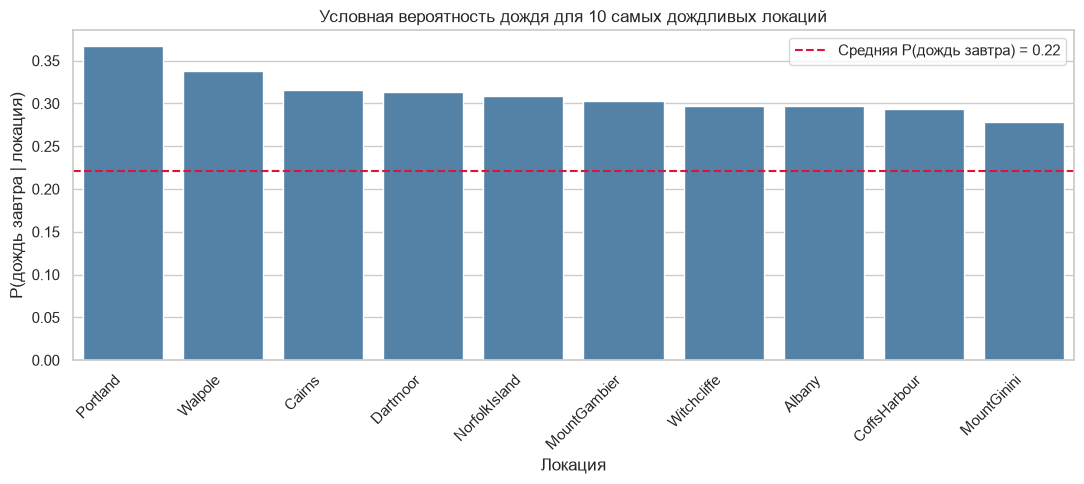

In [10]:
top = by_location.head(10)

plt.figure(figsize=(11, 5))
sns.barplot(x=top.index, y=top["P(дождь завтра)"], color="steelblue")
plt.axhline(p_rain, color="crimson", linestyle="--",
            label=f"Средняя P(дождь завтра) = {p_rain:.2f}")
plt.xticks(rotation=45, ha="right")
plt.xlabel("Локация")
plt.ylabel("P(дождь завтра | локация)")
plt.title("Условная вероятность дождя для 10 самых дождливых локаций")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Итоговое сравнение и выводы

Соберём все найденные условные вероятности в одну таблицу.


In [11]:
summary = pd.DataFrame(
    {
        "Условие": [
            "Без условий (априорная P)",
            "Сегодня дождь",
            "Сегодня сухо",
            "Влажность >= медианы",
            "Влажность < медианы",
        ],
        "P(дождь завтра)": [
            p_rain,
            p_rain_given_today,
            p_rain_given_dry,
            p_given_humid,
            p_given_dryair,
        ],
    }
)
summary["P(дождь завтра)"] = summary["P(дождь завтра)"].round(3)
summary["Отклонение от P"] = (
    summary["P(дождь завтра)"] - round(p_rain, 3)
).round(3)
display(summary)


,Условие,P(дождь завтра),Отклонение от P
0,Без условий (априорная P),0.222,0.000
1,Сегодня дождь,0.464,0.242
2,Сегодня сухо,0.152,-0.070
3,Влажность >= медианы,0.359,0.137
4,Влажность < медианы,0.087,-0.135


### Выводы

1. **Априорная вероятность** дождя завтра составляет примерно
   $P(\text{дождь завтра}) \approx 0.22$ — то есть по умолчанию дождливых дней
   около 22 %.
2. **`RainToday` — сильный предиктор.** Если сегодня шёл дождь, вероятность
   дождя завтра заметно выше средней; если сегодня сухо — ниже. Признаки
   зависимы.
3. **Влажность в 15:00 тоже информативна:** при влажности не меньше медианы
   вероятность дождя завтра существенно выше, чем при сухом воздухе.
4. **Локация влияет на вероятность:** разница между самыми дождливыми и самыми
   сухими городами Австралии очень велика.
5. Совместный учёт нескольких условий (влажность **и** дождь сегодня) даёт ещё
   более выраженные различия — это наглядно видно на тепловой карте.

Так условные вероятности позволяют не просто описывать данные, но и
**количественно измерять силу связи** между признаками.
